# Amazon Review Intelligence System

**Dataset:** Amazon customer reviews, *All Beauty* category (20,000-review sample, `all_beauty_reviews_sample_20000.jsonl`)

## Project Objective
Analyze Amazon customer reviews using Apache PySpark.

### Goals
- Explore customer reviews and ratings.
- Clean and preprocess review data.
- Identify customer sentiment.
- Build a machine learning classification model.
- Evaluate model performance.
- Explore the structure of the reviews with unsupervised methods (K-Means, hierarchical clustering, PCA, LDA).

### Contents
1. Setup
2. Load & Inspect Data
3. Data Quality Checks
4. Cleaning & Feature Preparation
5. Sentiment Exploration
6. Text Preprocessing & TF-IDF
7. Sentiment Classification (Logistic Regression, Naive Bayes, Decision Tree, Random Forest)
8. Unsupervised Analysis (K-Means, PCA, Hierarchical Clustering, LDA)
9. Summary

## 1. Setup

### 1.1 Imports
All imports live in this one cell.

In [2]:
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA as SkPCA

from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, concat_ws, length, lower, regexp_replace, trim, udf, when,
    round as spark_round,
    sum as spark_sum,
)
from pyspark.sql.types import IntegerType
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Tokenizer, StopWordsRemover, CountVectorizer, IDF, StringIndexer, PCA,
)
from pyspark.ml.classification import (
    LogisticRegression, NaiveBayes, DecisionTreeClassifier, RandomForestClassifier,
)
from pyspark.ml.clustering import KMeans, LDA
from pyspark.ml.evaluation import (
    MulticlassClassificationEvaluator, ClusteringEvaluator,
)

print("Libraries imported successfully!")

Libraries imported successfully!


### 1.2 Spark session

In [3]:
spark = (
    SparkSession.builder
    .appName("AmazonReviewIntelligence")
    .master("local[*]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark Version:", spark.version)

Spark Version: 3.5.9


## 2. Load & Inspect Data

In [4]:
df = spark.read.json(
    "all_beauty_reviews_sample_20000.jsonl"
)

print("Dataset loaded successfully!")
print("Total reviews:", df.count())

Dataset loaded successfully!
Total reviews: 20000


In [5]:
df.printSchema()

print("Columns:", df.columns)

df.show(5, truncate=False)

root
 |-- asin: string (nullable = true)
 |-- helpful_vote: long (nullable = true)
 |-- images: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- attachment_type: string (nullable = true)
 |    |    |-- large_image_url: string (nullable = true)
 |    |    |-- medium_image_url: string (nullable = true)
 |    |    |-- small_image_url: string (nullable = true)
 |-- parent_asin: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- text: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- title: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- verified_purchase: boolean (nullable = true)

Columns: ['asin', 'helpful_vote', 'images', 'parent_asin', 'rating', 'text', 'timestamp', 'title', 'user_id', 'verified_purchase']
+----------+------------+------+-----------+------+------------------------------------------------------------------------------------------------------------------------------------------

## 3. Data Quality Checks

### 3.1 Missing values

In [6]:
missing_values = df.select([
    spark_sum(when(col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in df.columns
])

missing_values.show()

+----+------------+------+-----------+------+----+---------+-----+-------+-----------------+
|asin|helpful_vote|images|parent_asin|rating|text|timestamp|title|user_id|verified_purchase|
+----+------------+------+-----------+------+----+---------+-----+-------+-----------------+
|   0|           0|     0|          0|     0|   0|        0|    0|      0|                0|
+----+------------+------+-----------+------+----+---------+-----+-------+-----------------+



### 3.2 Rating distribution

In [7]:
df.groupBy("rating").count().orderBy("rating").show()

+------+-----+
|rating|count|
+------+-----+
|   1.0| 1901|
|   2.0| 1206|
|   3.0| 1924|
|   4.0| 3034|
|   5.0|11935|
+------+-----+



### 3.3 Duplicates

In [8]:
print("Total rows:", df.count())

print(
    "Duplicate rows:",
    df.count() - df.dropDuplicates().count()
)

Total rows: 20000
Duplicate rows: 36


In [9]:
df_clean = df.dropDuplicates()

print("Original records:", df.count())
print("Records after removing duplicates:", df_clean.count())
print("Duplicates removed:", df.count() - df_clean.count())

Original records: 20000
Records after removing duplicates: 19964
Duplicates removed: 36


In [10]:
df_clean.printSchema()
df_clean.show(5, truncate=False)

root
 |-- asin: string (nullable = true)
 |-- helpful_vote: long (nullable = true)
 |-- images: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- attachment_type: string (nullable = true)
 |    |    |-- large_image_url: string (nullable = true)
 |    |    |-- medium_image_url: string (nullable = true)
 |    |    |-- small_image_url: string (nullable = true)
 |-- parent_asin: string (nullable = true)
 |-- rating: double (nullable = true)
 |-- text: string (nullable = true)
 |-- timestamp: long (nullable = true)
 |-- title: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- verified_purchase: boolean (nullable = true)

+----------+------------+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

## 4. Cleaning & Feature Preparation

### 4.1 Select columns

In [11]:
df_selected = df_clean.select(
    "asin",
    "user_id",
    "rating",
    "title",
    "text",
    "helpful_vote",
    "verified_purchase",
    "timestamp"
)

df_selected.show(5, truncate=50)

+----------+----------------------------+------+--------------------------------------------------+--------------------------------------------------+------------+-----------------+-------------+
|      asin|                     user_id|rating|                                             title|                                              text|helpful_vote|verified_purchase|    timestamp|
+----------+----------------------------+------+--------------------------------------------------+--------------------------------------------------+------------+-----------------+-------------+
|B08KT7FCYY|AFXF3EGQTQDXMRLDWFU7UBFQZB7Q|   2.0|Vegetal, messy flower balls; not sure why anyon...|I thought these were bath bombs when I ordered ...|           2|            false|1609804845102|
|B0895XRT9S|AFXF3EGQTQDXMRLDWFU7UBFQZB7Q|   3.0|Kid-sized shower caps; best used to cover small...|This single layer thin blue shower disposable s...|           0|            false|1598818621900|
|B07P83R5GT|AH74JVFA

### 4.2 Combine title and text into one review field

In [12]:
df_selected = df_selected.withColumn(
    "review_text",
    trim(concat_ws(" ", col("title"), col("text")))
)

df_selected.select("title", "text", "review_text").show(
    5, truncate=100
)

+------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|                                                                               title|                                                                                                text|                                                                                         review_text|
+------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|Vegetal, messy flower balls; not sure why anyone would use this for anything but tea|I thought these were bath bombs when I ordered 

In [13]:
df_selected = df_selected.filter(
    (col("review_text").isNotNull()) &
    (length(col("review_text")) > 0)
)

print("Reviews after text cleaning:", df_selected.count())

Reviews after text cleaning: 19964


### 4.3 Sentiment labels
Rating 1-2 → **Negative**, 3 → **Neutral**, 4-5 → **Positive**.

In [14]:
df_sentiment = df_selected.withColumn(
    "sentiment",
    when(col("rating") <= 2, "Negative")
    .when(col("rating") == 3, "Neutral")
    .otherwise("Positive")
)

df_sentiment.select(
    "rating", "sentiment", "review_text"
).show(10, truncate=80)

+------+---------+--------------------------------------------------------------------------------+
|rating|sentiment|                                                                     review_text|
+------+---------+--------------------------------------------------------------------------------+
|   2.0| Negative|Vegetal, messy flower balls; not sure why anyone would use this for anything ...|
|   3.0|  Neutral|Kid-sized shower caps; best used to cover small serving bowls This single lay...|
|   5.0| Positive|Awesome Product Use this stuff a lot - always ordering more as I use it frequ...|
|   5.0| Positive|Great quality I bought these for my 3 year old daughter who is moon obsessed....|
|   1.0| Negative|                         Don't waste money Does not work. Comes right off finger|
|   4.0| Positive|Nice but stays greasy for quite a bit This is a pretty nice face oil. It come...|
|   5.0| Positive|Banana Cream Pie Scent When I first tried this Marshmallow Vanishing Crème in...|


## 5. Sentiment Exploration

In [15]:
df_sentiment.groupBy("sentiment") \
    .count() \
    .orderBy("sentiment") \
    .show()

+---------+-----+
|sentiment|count|
+---------+-----+
| Negative| 3103|
|  Neutral| 1922|
| Positive|14939|
+---------+-----+



In [16]:
total = df_sentiment.count()

df_sentiment.groupBy("sentiment").count() \
    .withColumn(
        "percentage",
        col("count") / total * 100
    ) \
    .show()

+---------+-----+------------------+
|sentiment|count|        percentage|
+---------+-----+------------------+
|  Neutral| 1922| 9.627329192546584|
| Positive|14939| 74.82969344820677|
| Negative| 3103|15.542977359246644|
+---------+-----+------------------+



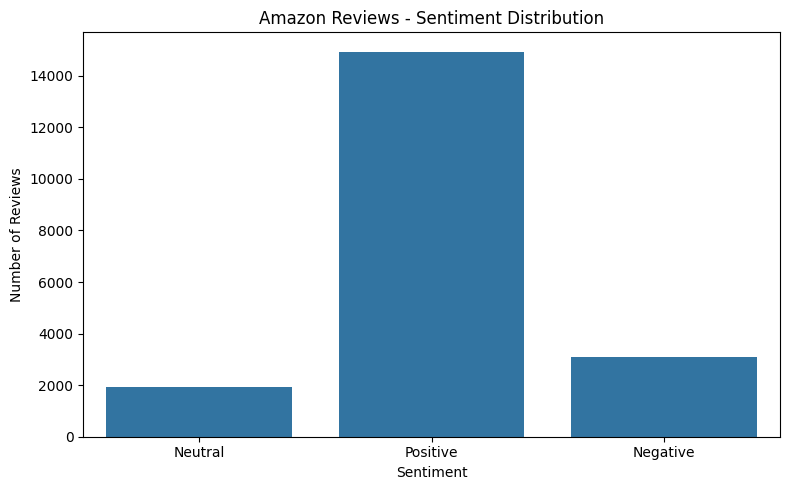

In [17]:
# Aggregate data using PySpark
sentiment_counts = (
    df_sentiment.groupBy("sentiment")
    .count()
    .toPandas()
)

# Create bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=sentiment_counts,
    x="sentiment",
    y="count"
)

plt.title("Amazon Reviews - Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

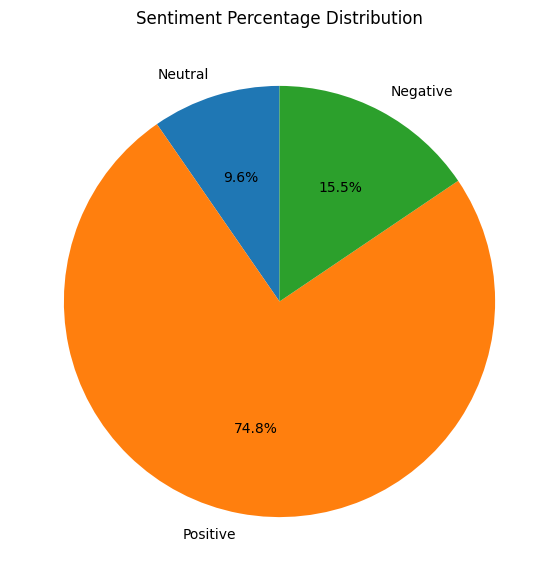

In [18]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts["count"],
    labels=sentiment_counts["sentiment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sentiment Percentage Distribution")
plt.show()

## 6. Text Preprocessing & TF-IDF

### 6.1 Clean text
Lowercase, strip punctuation, collapse whitespace.

In [19]:
df_processed = df_sentiment.withColumn(
    "clean_text",
    lower(col("review_text"))
)

df_processed = df_processed.withColumn(
    "clean_text",
    regexp_replace(col("clean_text"), "[^a-zA-Z0-9\\s]", "")
)

df_processed = df_processed.withColumn(
    "clean_text",
    trim(regexp_replace(col("clean_text"), "\\s+", " "))
)

print("Text preprocessing completed!")

Text preprocessing completed!


### 6.2 Tokenize

In [20]:
tokenizer = Tokenizer(
    inputCol="clean_text",
    outputCol="words"
)

tokenized_df = tokenizer.transform(df_processed)

tokenized_df.select(
    "clean_text", "words"
).show(5, truncate=100)

+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|                                                                                          clean_text|                                                                                               words|
+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|vegetal messy flower balls not sure why anyone would use this for anything but tea i thought thes...|[vegetal, messy, flower, balls, not, sure, why, anyone, would, use, this, for, anything, but, tea...|
|kidsized shower caps best used to cover small serving bowls this single layer thin blue shower di...|[kidsized, shower, caps, best, used, to, cover, small, serving, bowls, this, singl

### 6.3 Remove stop words
Negation words (`not`, `no`, `nor`) are kept because they carry sentiment.

In [21]:
remover = StopWordsRemover(
    inputCol="words",
    outputCol="filtered_words"
)

# Preserve negation words such as not and no
default_stop_words = remover.getStopWords()

custom_stop_words = [
    word for word in default_stop_words
    if word not in ["not", "no", "nor"]
]

remover.setStopWords(custom_stop_words)

filtered_df = remover.transform(tokenized_df)

filtered_df.select(
    "words",
    "filtered_words"
).show(5, truncate=100)

+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|                                                                                               words|                                                                                      filtered_words|
+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+
|[vegetal, messy, flower, balls, not, sure, why, anyone, would, use, this, for, anything, but, tea...|[vegetal, messy, flower, balls, not, sure, anyone, use, anything, tea, thought, bath, bombs, orde...|
|[kidsized, shower, caps, best, used, to, cover, small, serving, bowls, this, single, layer, thin,...|[kidsized, shower, caps, best, used, cover, small, serving, bowls, single, layer, 

### 6.4 TF-IDF features

In [22]:
cv = CountVectorizer(
    inputCol="filtered_words",
    outputCol="raw_features",
    vocabSize=10000,
    minDF=2
)

cv_model = cv.fit(filtered_df)

featurized_df = cv_model.transform(filtered_df)

In [23]:
idf = IDF(
    inputCol="raw_features",
    outputCol="tfidf_features"
)

idf_model = idf.fit(featurized_df)

final_df = idf_model.transform(featurized_df)

In [24]:
final_df.select(
    "clean_text",
    "sentiment",
    "tfidf_features"
).show(5, truncate=100)

vocabulary = cv_model.vocabulary

print("Total vocabulary words:", len(vocabulary))
print("First 30 words:", vocabulary[:30])

+----------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------------------------------------------+
|                                                                                          clean_text|sentiment|                                                                                      tfidf_features|
+----------------------------------------------------------------------------------------------------+---------+----------------------------------------------------------------------------------------------------+
|vegetal messy flower balls not sure why anyone would use this for anything but tea i thought thes...| Negative|(10000,[0,3,4,9,10,17,18,19,27,28,29,42,49,59,80,89,100,103,106,108,114,125,136,141,172,197,216,2...|
|kidsized shower caps best used to cover small serving bowls this single layer thin blue shower di...|  Neutral|(10000,[0,1,12,14,18,23,46,56,89

## 7. Sentiment Classification

### 7.1 Train / test split (80 / 20)

In [25]:
train_df, test_df = df_processed.randomSplit(
    [0.8, 0.2],
    seed=42
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

Training records: 16093
Testing records: 3871


### 7.2 Logistic Regression

**Pipeline:** tokenizer → stop words → count vectorizer → IDF → label indexer → classifier.

In [26]:
# 1. Tokenization
tokenizer = Tokenizer(
    inputCol="clean_text",
    outputCol="words"
)

# 2. Stop-word removal
remover = StopWordsRemover(
    inputCol="words",
    outputCol="filtered_words"
)

stop_words = [
    word for word in remover.getStopWords()
    if word not in ["not", "no", "nor"]
]
remover.setStopWords(stop_words)

# 3. Convert words into numerical counts
cv = CountVectorizer(
    inputCol="filtered_words",
    outputCol="raw_features",
    vocabSize=10000,
    minDF=2
)

# 4. Calculate TF-IDF
idf = IDF(
    inputCol="raw_features",
    outputCol="features"
)

# 5. Convert sentiment labels into numerical labels
indexer = StringIndexer(
    inputCol="sentiment",
    outputCol="label"
)

# 6. Logistic Regression model
lr = LogisticRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=50,
    regParam=0.01
)

# Connect all stages
pipeline = Pipeline(stages=[
    tokenizer,
    remover,
    cv,
    idf,
    indexer,
    lr
])

print("ML pipeline created successfully!")

ML pipeline created successfully!


**Train and predict**

In [27]:
model = pipeline.fit(train_df)

print("Model training completed!")

predictions = model.transform(test_df)

predictions.select(
    "clean_text",
    "sentiment",
    "label",
    "prediction",
    "probability"
).show(10, truncate=50)

Model training completed!
+--------------------------------------------------+---------+-----+----------+--------------------------------------------------+
|                                        clean_text|sentiment|label|prediction|                                       probability|
+--------------------------------------------------+---------+-----+----------+--------------------------------------------------+
|best electric for the price my dentist was push...| Positive|  0.0|       2.0|[0.18243972336329894,0.012981953126250048,0.804...|
|did not shave close for me this unit is well de...|  Neutral|  2.0|       0.0|[0.9998925661375412,3.364555184168906E-5,7.3788...|
|great bargain like many others i checked into t...| Positive|  0.0|       0.0|[0.976571221700412,0.019429422748353815,0.00399...|
|love the hardtofind 1 12 barrel the one id been...| Positive|  0.0|       0.0|[0.9237836610793467,0.0634433419040221,0.012772...|
|did not work for my thin nails i have yet to fi...| Nega

**Overall metrics and confusion table**

In [28]:
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="accuracy"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="f1"
)

accuracy = accuracy_evaluator.evaluate(predictions)
f1_score = f1_evaluator.evaluate(predictions)

print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("F1 Score:", round(f1_score, 4))

confusion_df = (
    predictions
    .groupBy("label", "prediction")
    .count()
    .orderBy("label", "prediction")
)

confusion_df.show()

Model Accuracy: 82.87 %
F1 Score: 0.8194
+-----+----------+-----+
|label|prediction|count|
+-----+----------+-----+
|  0.0|       0.0| 2724|
|  0.0|       1.0|   81|
|  0.0|       2.0|  110|
|  1.0|       0.0|  126|
|  1.0|       1.0|  384|
|  1.0|       2.0|   61|
|  2.0|       0.0|  192|
|  2.0|       1.0|   93|
|  2.0|       2.0|  100|
+-----+----------+-----+



**Per-class precision and recall**

In [29]:
# Map numeric labels back to sentiment names using the fitted StringIndexer.
# (StringIndexer orders labels by frequency, so this stays correct if the data changes.)
classes = {float(i): name for i, name in enumerate(model.stages[4].labelsArray[0])}


def print_per_class_metrics(preds):
    """Print precision and recall for each sentiment class."""
    for label, sentiment in classes.items():

        precision_evaluator = MulticlassClassificationEvaluator(
            labelCol="label",
            predictionCol="prediction",
            metricName="precisionByLabel",
            metricLabel=label
        )

        recall_evaluator = MulticlassClassificationEvaluator(
            labelCol="label",
            predictionCol="prediction",
            metricName="recallByLabel",
            metricLabel=label
        )

        precision = precision_evaluator.evaluate(preds)
        recall = recall_evaluator.evaluate(preds)

        print(f"\n{sentiment}")
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))


print_per_class_metrics(predictions)


Positive
Precision: 0.8955
Recall: 0.9345

Negative
Precision: 0.6882
Recall: 0.6725

Neutral
Precision: 0.369
Recall: 0.2597


**Confusion matrix**

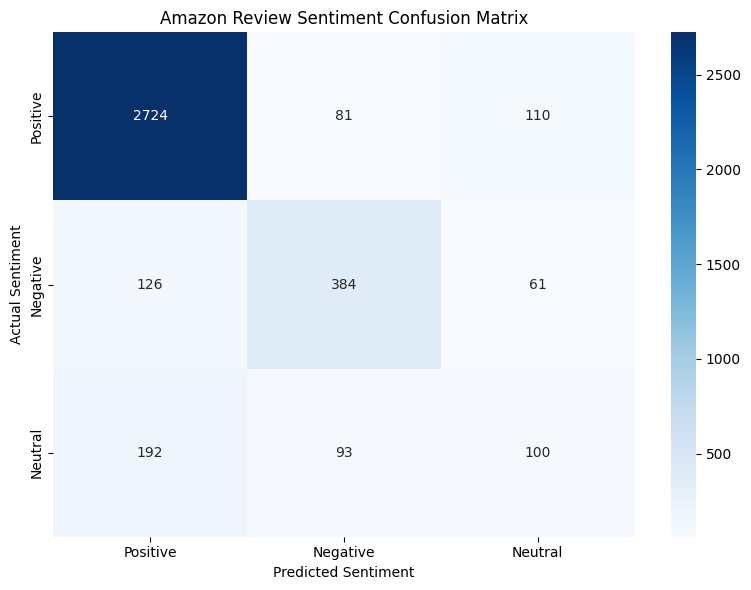

In [30]:
# Convert the small Spark result into Pandas
confusion_pd = confusion_df.toPandas()

# Create confusion matrix
matrix = confusion_pd.pivot(
    index="label",
    columns="prediction",
    values="count"
).fillna(0)

# Add sentiment names
matrix.index = [classes[i] for i in matrix.index]
matrix.columns = [classes[i] for i in matrix.columns]

# Plot heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title("Amazon Review Sentiment Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

### 7.3 Naive Bayes

In [31]:
nb = NaiveBayes(
    featuresCol="features",
    labelCol="label",
    modelType="multinomial",
    smoothing=1.0
)

nb_pipeline = Pipeline(stages=[
    tokenizer,
    remover,
    cv,
    idf,
    indexer,
    nb
])

print("Naive Bayes pipeline created!")
nb_model = nb_pipeline.fit(train_df)

print("Naive Bayes training completed!")
nb_predictions = nb_model.transform(test_df)

nb_accuracy = accuracy_evaluator.evaluate(nb_predictions)
nb_f1 = f1_evaluator.evaluate(nb_predictions)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")
print("Naive Bayes F1 Score:", round(nb_f1, 4))

Naive Bayes pipeline created!
Naive Bayes training completed!
Naive Bayes Accuracy: 77.91 %
Naive Bayes F1 Score: 0.7899


In [32]:
print_per_class_metrics(nb_predictions)


Positive
Precision: 0.9199
Recall: 0.8587

Negative
Precision: 0.5637
Recall: 0.6585

Neutral
Precision: 0.2836
Recall: 0.3558


### 7.4 Decision Tree

In [33]:
dt = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=10,
    maxBins=32
)

dt_pipeline = Pipeline(stages=[
    tokenizer,
    remover,
    cv,
    idf,
    indexer,
    dt
])

print("Decision Tree pipeline created!")
dt_model = dt_pipeline.fit(train_df)

print("Decision Tree training completed!")
dt_predictions = dt_model.transform(test_df)

dt_accuracy = accuracy_evaluator.evaluate(dt_predictions)
dt_f1 = f1_evaluator.evaluate(dt_predictions)

print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")
print("Decision Tree F1 Score:", round(dt_f1, 4))

Decision Tree pipeline created!
Decision Tree training completed!
Decision Tree Accuracy: 79.59 %
Decision Tree F1 Score: 0.7766


### 7.5 Random Forest
Uses a smaller vocabulary (2,000 terms) to keep training manageable.

In [34]:
rf_cv = CountVectorizer(
    inputCol="filtered_words",
    outputCol="raw_features",
    vocabSize=2000,
    minDF=2
)

rf_idf = IDF(
    inputCol="raw_features",
    outputCol="features"
)

rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=30,
    maxDepth=8,
    seed=42
)

rf_pipeline = Pipeline(stages=[
    tokenizer,
    remover,
    rf_cv,
    rf_idf,
    indexer,
    rf
])

print("Random Forest pipeline created!")

rf_model = rf_pipeline.fit(train_df)

print("Random Forest training completed!")

rf_predictions = rf_model.transform(test_df)

rf_accuracy = accuracy_evaluator.evaluate(rf_predictions)
rf_f1 = f1_evaluator.evaluate(rf_predictions)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")
print("Random Forest F1 Score:", round(rf_f1, 4))

Random Forest pipeline created!
Random Forest training completed!
Random Forest Accuracy: 75.33 %
Random Forest F1 Score: 0.6476


### 7.6 Model comparison

In [35]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Decision Tree",
        "Random Forest"
    ],
    # Values come straight from the evaluation cells above (no hand-typed numbers)
    "Accuracy": [
        round(accuracy * 100, 2),
        round(nb_accuracy * 100, 2),
        round(dt_accuracy * 100, 2),
        round(rf_accuracy * 100, 2)
    ],
    "Weighted F1": [
        round(f1_score, 4),
        round(nb_f1, 4),
        round(dt_f1, 4),
        round(rf_f1, 4)
    ]
})

model_comparison = model_comparison.sort_values(
    by="Weighted F1", ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy,Weighted F1
0,Logistic Regression,82.87,0.8194
1,Naive Bayes,77.91,0.7899
2,Decision Tree,79.59,0.7766
3,Random Forest,75.33,0.6476


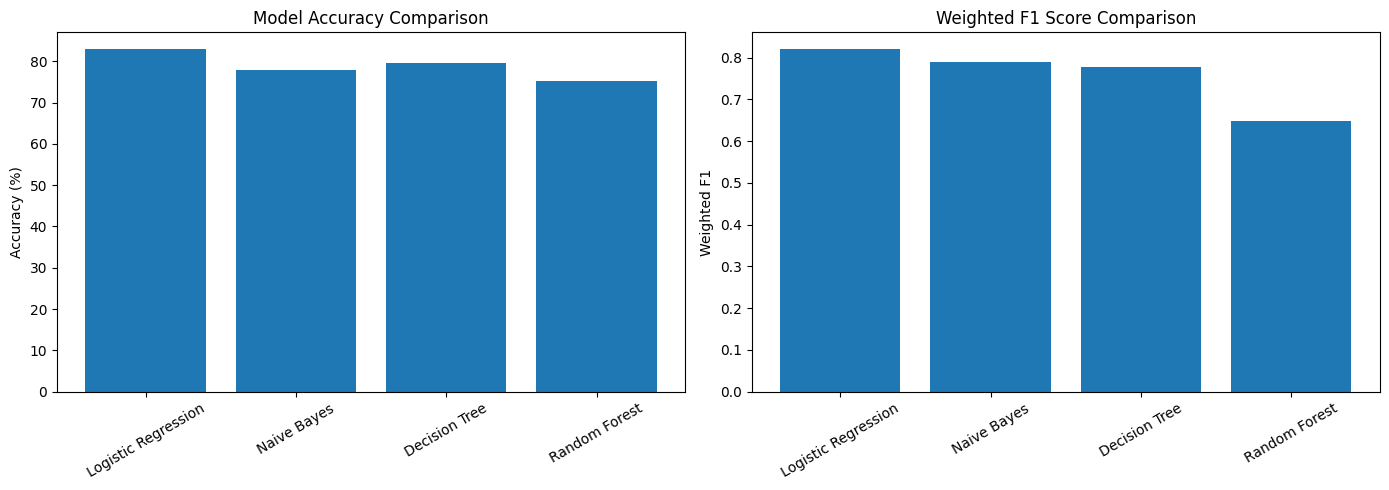

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(
    model_comparison["Model"],
    model_comparison["Accuracy"]
)
axes[0].set_title("Model Accuracy Comparison")
axes[0].set_ylabel("Accuracy (%)")
axes[0].tick_params(axis="x", rotation=30)

axes[1].bar(
    model_comparison["Model"],
    model_comparison["Weighted F1"]
)
axes[1].set_title("Weighted F1 Score Comparison")
axes[1].set_ylabel("Weighted F1")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [37]:
best_model = model_comparison.loc[
    model_comparison["Weighted F1"].idxmax()
]

print("BEST MODEL:", best_model["Model"])
print("Accuracy:", best_model["Accuracy"], "%")
print("Weighted F1:", best_model["Weighted F1"])

BEST MODEL: Logistic Regression
Accuracy: 82.87 %
Weighted F1: 0.8194


## 8. Unsupervised Analysis

### 8.1 K-Means on the full TF-IDF matrix (K = 5)

In [38]:
kmeans = KMeans(
    featuresCol="tfidf_features",
    predictionCol="cluster",
    k=5,
    seed=42,
    maxIter=20
)

kmeans_model = kmeans.fit(final_df)

print("K-Means training completed!")

cluster_predictions = kmeans_model.transform(final_df)

cluster_predictions.select(
    "review_text",
    "sentiment",
    "cluster"
).show(15, truncate=60)

cluster_predictions.groupBy("cluster") \
    .count() \
    .orderBy("cluster") \
    .show()

K-Means training completed!
+------------------------------------------------------------+---------+-------+
|                                                 review_text|sentiment|cluster|
+------------------------------------------------------------+---------+-------+
|Vegetal, messy flower balls; not sure why anyone would us...| Negative|      1|
|Kid-sized shower caps; best used to cover small serving b...|  Neutral|      0|
|Awesome Product Use this stuff a lot - always ordering mo...| Positive|      0|
|Great quality I bought these for my 3 year old daughter w...| Positive|      0|
|     Don't waste money Does not work. Comes right off finger| Negative|      0|
|Nice but stays greasy for quite a bit This is a pretty ni...| Positive|      1|
|Banana Cream Pie Scent When I first tried this Marshmallo...| Positive|      1|
|I have been using this product I used it daily until I pu...| Positive|      0|
|Don't. Just don't. Gummy, too opaque. Threw it in the Bad...| Negative|      0|


In [39]:
vocabulary = cv_model.vocabulary
centers = kmeans_model.clusterCenters()

for i, center in enumerate(centers):

    top_indices = np.argsort(center)[-15:][::-1]

    top_words = [vocabulary[j] for j in top_indices]

    print(f"\nCluster {i}")
    print("Top words:", top_words)

cluster_counts = (
    cluster_predictions
    .groupBy("cluster")
    .count()
    .orderBy("cluster")
)

cluster_counts.show(10, False)


Cluster 0
Top words: ['hair', 'not', 'great', 'love', 'good', 'product', 'like', 'use', 'nice', 'well', 'one', 'works', 'skin', 'really', 'stars']

Cluster 1
Top words: ['br', 'skin', 'hair', 'not', 'like', 'use', 'one', 'oil', 'product', 'face', 'really', 'also', 'using', 'get', 'no']

Cluster 2
Top words: ['shave', 'razor', 'norelco', 'charge', 'shaver', 'br', 'shaving', 'battery', 'braun', 'charger', 'razors', 'razer', 'electric', 'close', 'one']

Cluster 3
Top words: ['accent', 'soooooo', 'justice', 'pictures', 'fingerbr', 'pinky', 'sunlight', 'essie', 'paired', 'imo', 'topcoat', 'sparkles', 'thumb', 'ring', 'selection']

Cluster 4
Top words: ['agent', 'skin', 'br', '1', 'vitamin', 'retinol', 'acid', 'antioxidant', 'emollient', 'ingredient', 'humectant', 'sodium', 'emulsifying', 'hyaluronate', 'alcohol']
+-------+-----+
|cluster|count|
+-------+-----+
|0      |18492|
|1      |1439 |
|2      |28   |
|3      |1    |
|4      |4    |
+-------+-----+



**Silhouette score**

In [40]:
silhouette_sample = (
    cluster_predictions
    .select("tfidf_features", "cluster")
    .sample(False, 0.05, seed=42)
    .limit(1000)
)

evaluator = ClusteringEvaluator(
    featuresCol="tfidf_features",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

silhouette_score = evaluator.evaluate(silhouette_sample)

print("Silhouette Score:", round(silhouette_score, 4))

Silhouette Score: 0.6951


### 8.2 Reduced feature space
A 500-term TF-IDF matrix used by the remaining unsupervised steps (K selection, PCA, hierarchical clustering).

In [41]:
small_cv = CountVectorizer(
    inputCol="filtered_words",
    outputCol="small_raw",
    vocabSize=500,
    minDF=2
)

small_cv_model = small_cv.fit(filtered_df)
small_features = small_cv_model.transform(filtered_df)

small_idf = IDF(
    inputCol="small_raw",
    outputCol="small_tfidf"
)

small_idf_model = small_idf.fit(small_features)
small_features = small_idf_model.transform(small_features)

### 8.3 K-Means: choosing K and final model (on a 1,000-review sample)

In [42]:
evaluation_data = small_features.select("small_tfidf").sample(
    False, 0.05, seed=42
).limit(1000)

scores = []

for k in [2, 3, 4, 5]:
    km = KMeans(
        k=k,
        featuresCol="small_tfidf",
        predictionCol="cluster",
        seed=42,
        maxIter=20
    )

    km_model = km.fit(evaluation_data)
    km_predictions = km_model.transform(evaluation_data)

    evaluator = ClusteringEvaluator(
        featuresCol="small_tfidf",
        predictionCol="cluster",
        metricName="silhouette",
        distanceMeasure="squaredEuclidean"
    )

    score = evaluator.evaluate(km_predictions)
    scores.append((k, score))

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.6156
K = 3, Silhouette Score = 0.6159
K = 4, Silhouette Score = 0.3673
K = 5, Silhouette Score = 0.7036


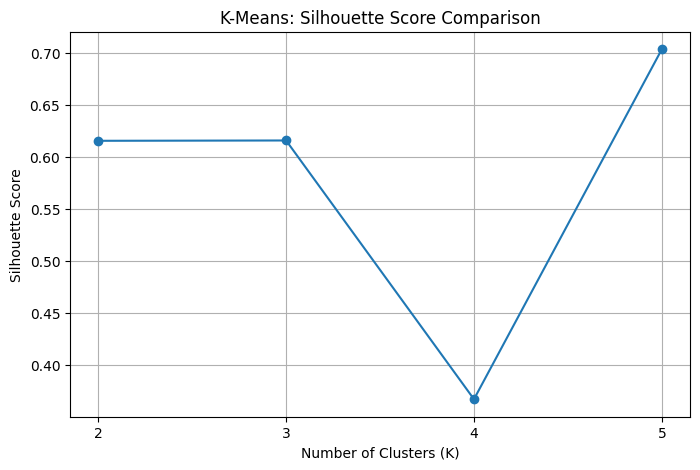

In [43]:
k_values = [x[0] for x in scores]
silhouette_values = [x[1] for x in scores]

plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_values, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette Score Comparison")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [44]:
# 1. Prepare evaluation data
evaluation_data = (
    small_features
    .select("small_tfidf", "sentiment")
    .sample(False, 0.05, seed=42)
    .limit(1000)
    .cache()
)

print("Total sampled reviews:", evaluation_data.count())

# 2. Train K-Means with K = 5
best_kmeans = KMeans(
    k=5,
    featuresCol="small_tfidf",
    predictionCol="cluster",
    seed=42,
    maxIter=20
)

best_kmeans_model = best_kmeans.fit(evaluation_data)

# 3. Generate predictions
best_predictions = best_kmeans_model.transform(evaluation_data).cache()

print("\nK-Means training completed!")

# 4. Display cluster sizes
print("\nCLUSTER SIZES")

cluster_sizes = (
    best_predictions
    .groupBy("cluster")
    .count()
    .orderBy("cluster")
)

cluster_sizes.show()

# 5. Display sentiment distribution
print("\nSENTIMENT DISTRIBUTION")

cluster_sentiment_counts = (
    best_predictions
    .groupBy("cluster", "sentiment")
    .count()
    .orderBy("cluster", "sentiment")
)

cluster_sentiment_counts.show()

# 6. Calculate sentiment percentages
print("\nSENTIMENT PERCENTAGES")

cluster_percentages = (
    best_predictions
    .groupBy("cluster")
    .pivot("sentiment", ["Negative", "Neutral", "Positive"])
    .count()
    .na.fill(0)
)

total_per_cluster = cluster_percentages.select(
    "cluster",
    (
        col("Negative") +
        col("Neutral") +
        col("Positive")
    ).alias("total")
)

cluster_percentages = cluster_percentages.join(
    total_per_cluster, on="cluster"
)

cluster_percentages.select(
    "cluster",
    *[
        spark_round(col(c) / col("total") * 100, 2).alias(c)
        for c in ["Negative", "Neutral", "Positive"]
    ]
).orderBy("cluster").show()

# 7. Calculate Silhouette Score
evaluator = ClusteringEvaluator(
    featuresCol="small_tfidf",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

silhouette_score = evaluator.evaluate(best_predictions)

print("\nFINAL SILHOUETTE SCORE:", round(silhouette_score, 4))

Total sampled reviews: 1000

K-Means training completed!

CLUSTER SIZES
+-------+-----+
|cluster|count|
+-------+-----+
|      0|  996|
|      1|    1|
|      2|    1|
|      3|    1|
|      4|    1|
+-------+-----+


SENTIMENT DISTRIBUTION
+-------+---------+-----+
|cluster|sentiment|count|
+-------+---------+-----+
|      0| Negative|  169|
|      0|  Neutral|   94|
|      0| Positive|  733|
|      1|  Neutral|    1|
|      2| Positive|    1|
|      3| Negative|    1|
|      4| Positive|    1|
+-------+---------+-----+


SENTIMENT PERCENTAGES
+-------+--------+-------+--------+
|cluster|Negative|Neutral|Positive|
+-------+--------+-------+--------+
|      0|   16.97|   9.44|   73.59|
|      1|     0.0|  100.0|     0.0|
|      2|     0.0|    0.0|   100.0|
|      3|   100.0|    0.0|     0.0|
|      4|     0.0|    0.0|   100.0|
+-------+--------+-------+--------+


FINAL SILHOUETTE SCORE: 0.6787


### 8.4 PCA (2 components)

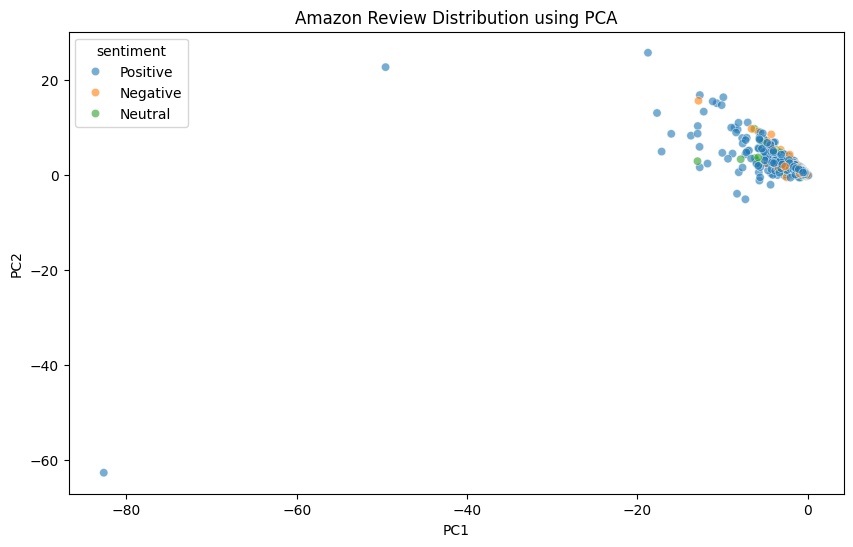

In [45]:
pca_sample = small_features.sample(
    False, 0.05, seed=42
)

pca = PCA(
    k=2,
    inputCol="small_tfidf",
    outputCol="pca_features"
)

pca_model = pca.fit(pca_sample)
pca_result = pca_model.transform(pca_sample)

pandas_df = pca_result.select(
    "pca_features", "sentiment"
).toPandas()

pandas_df["PC1"] = pandas_df["pca_features"].apply(lambda x: float(x[0]))
pandas_df["PC2"] = pandas_df["pca_features"].apply(lambda x: float(x[1]))

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pandas_df,
    x="PC1",
    y="PC2",
    hue="sentiment",
    alpha=0.6
)

plt.title("Amazon Review Distribution using PCA")
plt.show()

### 8.5 Hierarchical (agglomerative) clustering

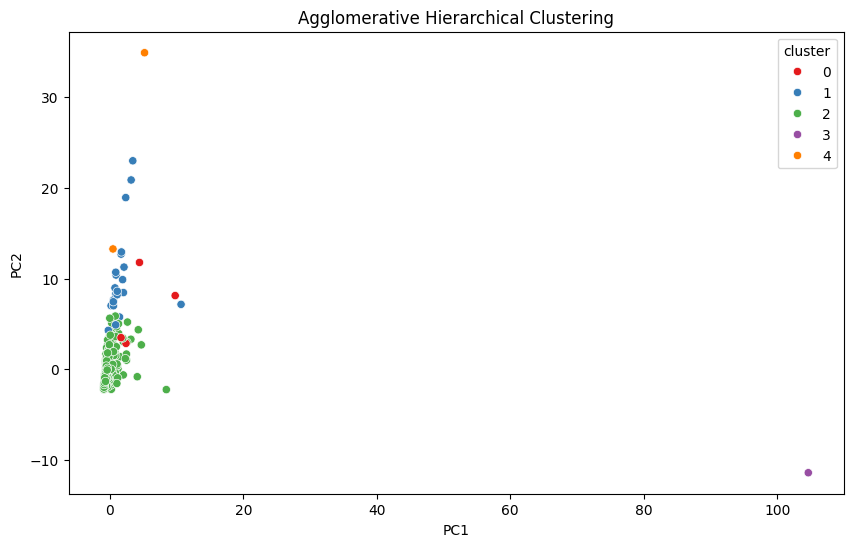

In [46]:
hierarchy_sample = small_features.select(
    "small_tfidf", "sentiment"
).sample(False, 0.025, seed=42).limit(500)

hierarchy_pd = hierarchy_sample.toPandas()

X = np.array([
    vector.toArray()
    for vector in hierarchy_pd["small_tfidf"]
])

y = hierarchy_pd["sentiment"]

hc = AgglomerativeClustering(
    n_clusters=5,
    linkage="ward"
)

hierarchy_pd["cluster"] = hc.fit_predict(X)

sk_pca = SkPCA(n_components=2, random_state=42)
X_2d = sk_pca.fit_transform(X)

hierarchy_pd["PC1"] = X_2d[:, 0]
hierarchy_pd["PC2"] = X_2d[:, 1]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=hierarchy_pd,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set1"
)

plt.title("Agglomerative Hierarchical Clustering")
plt.show()

In [47]:
# 1. Number of reviews in each cluster
print("CLUSTER COUNTS")
display(
    hierarchy_pd["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Total Reviews")
)

# 2. Sentiment counts in each cluster
cluster_summary = pd.crosstab(
    hierarchy_pd["cluster"],
    hierarchy_pd["sentiment"],
    margins=True
)

print("\nSENTIMENT COUNTS")
display(cluster_summary)

# 3. Sentiment percentages in each cluster
cluster_percentages = pd.crosstab(
    hierarchy_pd["cluster"],
    hierarchy_pd["sentiment"],
    normalize="index"
) * 100

print("\nSENTIMENT PERCENTAGES")
display(cluster_percentages.round(2))

CLUSTER COUNTS


,Total Reviews
cluster,
0,4
1,24
2,457
3,1
4,2



SENTIMENT COUNTS


sentiment,Negative,Neutral,Positive,All
cluster,,,,
0,0,0,4,4
1,3,2,19,24
2,63,37,357,457
3,0,0,1,1
4,1,0,1,2
All,67,39,382,488



SENTIMENT PERCENTAGES


sentiment,Negative,Neutral,Positive
cluster,,,
0,0.00,0.00,100.00
1,12.50,8.33,79.17
2,13.79,8.10,78.12
3,0.00,0.00,100.00
4,50.00,0.00,50.00


### 8.6 LDA topic modelling (5 topics)

In [48]:
lda_cv = CountVectorizer(
    inputCol="filtered_words",
    outputCol="lda_features",
    vocabSize=3000,
    minDF=3
)

lda_cv_model = lda_cv.fit(filtered_df)
lda_data = lda_cv_model.transform(filtered_df)

lda = LDA(
    k=5,
    maxIter=10,
    featuresCol="lda_features",
    seed=42
)

lda_model = lda.fit(lda_data)

topics = lda_model.describeTopics(maxTermsPerTopic=10)
lda_vocab = lda_cv_model.vocabulary

for topic in topics.collect():
    words = [lda_vocab[i] for i in topic["termIndices"]]
    print(f"Topic {topic['topic']}: {words}")

Topic 0: ['hair', 'not', 'brush', 'like', 'love', 'great', 'wig', 'use', 'well', 'head']
Topic 1: ['not', 'use', 'one', 'like', 'great', 'br', 'get', 'easy', 'dont', 'good']
Topic 2: ['well', 'not', 'product', 'hair', 'brush', 'gift', 'works', 'use', 'loves', 'great']
Topic 3: ['skin', 'not', 'use', 'product', 'br', 'like', 'face', 'great', 'cream', 'using']
Topic 4: ['great', 'not', 'good', 'love', 'product', 'hair', 'stars', 'like', 'nice', 'use']


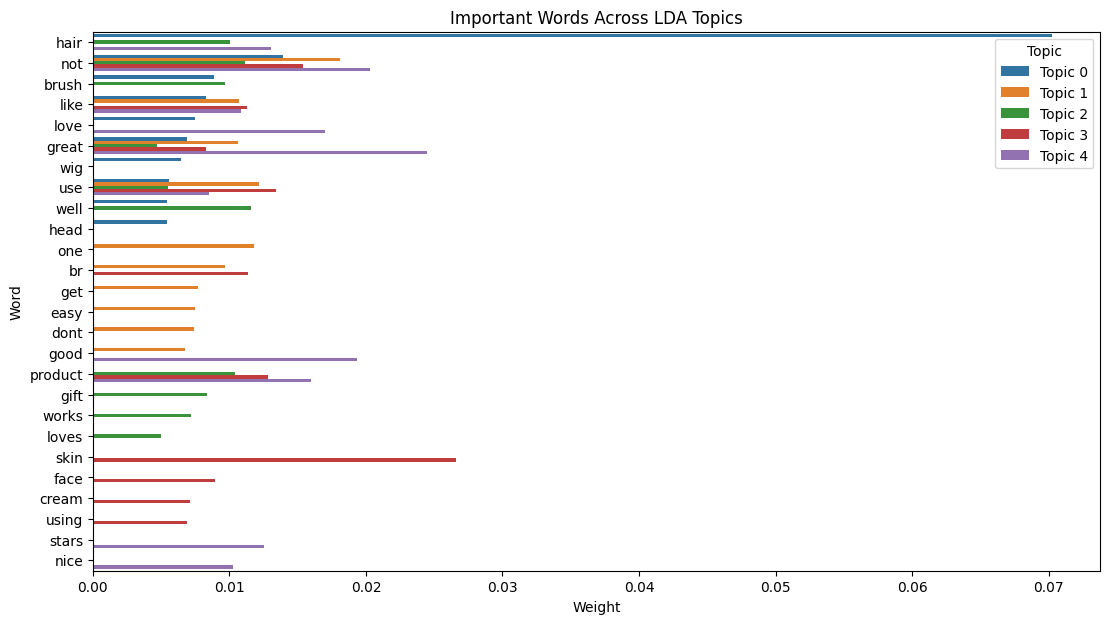

In [49]:
topic_data = []

for topic in topics.collect():
    words = [lda_vocab[i] for i in topic["termIndices"]]
    weights = topic["termWeights"]

    for word, weight in zip(words, weights):
        topic_data.append({
            "Topic": f"Topic {topic['topic']}",
            "Word": word,
            "Weight": float(weight)
        })

topic_pd = pd.DataFrame(topic_data)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=topic_pd,
    x="Weight",
    y="Word",
    hue="Topic"
)

plt.title("Important Words Across LDA Topics")
plt.show()

In [50]:
lda_predictions = lda_model.transform(lda_data)

def get_dominant_topic(vector):
    return int(max(range(len(vector)), key=lambda i: vector[i]))

dominant_topic_udf = udf(get_dominant_topic, IntegerType())

lda_predictions = lda_predictions.withColumn(
    "dominant_topic",
    dominant_topic_udf(col("topicDistribution"))
)

topic_distribution = (
    lda_predictions
    .groupBy("dominant_topic")
    .count()
    .orderBy("dominant_topic")
)

topic_distribution.show()

+--------------+-----+
|dominant_topic|count|
+--------------+-----+
|             0| 2093|
|             1| 5474|
|             2|  550|
|             3| 3838|
|             4| 8009|
+--------------+-----+



## 9. Summary

In [51]:
unsupervised_comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical Clustering",
        "LDA",
        "PCA"
    ],
    "Purpose": [
        "Customer/review grouping",
        "Hierarchical grouping",
        "Topic discovery",
        "Dimensionality reduction"
    ],
    "Result": [
        "5 clusters; highly imbalanced",
        "5 clusters; highly imbalanced",
        "5 topics identified",
        "500 features reduced to 2"
    ],
    "Assessment": [
        "Needs improvement",
        "Needs improvement",
        "Useful for topic discovery",
        "Useful for visualization"
    ]
})

unsupervised_comparison

,Algorithm,Purpose,Result,Assessment
0,K-Means,Customer/review grouping,5 clusters; highly imbalanced,Needs improvement
1,Hierarchical Clustering,Hierarchical grouping,5 clusters; highly imbalanced,Needs improvement
2,LDA,Topic discovery,5 topics identified,Useful for topic discovery
3,PCA,Dimensionality reduction,500 features reduced to 2,Useful for visualization


In [52]:
print("=" * 55)
print("AMAZON REVIEW INTELLIGENCE SYSTEM")
print("=" * 55)

print("\nBEST SENTIMENT CLASSIFICATION MODEL")
print("Model:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']}%")
print(f"Weighted F1: {best_model['Weighted F1']}")

print("\nBEST TOPIC MODELLING APPROACH")
print("LDA - 5 topics identified")

print("\nFINAL CONCLUSION")
print("Logistic Regression is the best completed")
print("sentiment classification model.")
print("LDA is useful for discovering review topics.")
print("K-Means and Hierarchical clustering need improvement.")

AMAZON REVIEW INTELLIGENCE SYSTEM

BEST SENTIMENT CLASSIFICATION MODEL
Model: Logistic Regression
Accuracy: 82.87%
Weighted F1: 0.8194

BEST TOPIC MODELLING APPROACH
LDA - 5 topics identified

FINAL CONCLUSION
Logistic Regression is the best completed
sentiment classification model.
LDA is useful for discovering review topics.
K-Means and Hierarchical clustering need improvement.


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 56795)
Traceback (most recent call last):
  File "C:\Users\AYUSH PANDEY\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 316, in _handle_request_noblock
    self.process_request(request, client_address)
  File "C:\Users\AYUSH PANDEY\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 347, in process_request
    self.finish_request(request, client_address)
  File "C:\Users\AYUSH PANDEY\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 360, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "C:\Users\AYUSH PANDEY\AppData\Local\Programs\Python\Python310\lib\socketserver.py", line 747, in __init__
    self.handle()
  File "d:\Cluster project\.venv\lib\site-packages\pyspark\accumulators.py", line 295, in handle
    poll(accum_updates)
  File "d:\Cluster project\.venv\lib\site-packages\pyspark\accumulat